# EDA for our raw data

## Importing dataset and libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("rawdataproject.csv") 

## Cleaning and reviewing the data


In [3]:
df.columns = df.columns.str.strip()

# Print basic information to review the dataset structure
print(" DATASET OVERVIEW ")
print(df.info())
print("\n MISSING VALUES (BEFORE CLEANING) ")
missing_before = df.isnull().sum()
print(missing_before[missing_before > 0])

# Identify numerical columns that have missing values
numeric_cols = df.select_dtypes(include=[np.number]).columns
numeric_cols_with_na = numeric_cols[df[numeric_cols].isnull().any()]

# This preserves the variance better than global mean imputation.
for col in numeric_cols_with_na:
    df[col] = df.groupby('Status')[col].transform(lambda x: x.fillna(x.median()))

# Looking for remaining NaN's
remaining_na = df[numeric_cols_with_na].isnull().sum().sum()
if remaining_na > 0:
    df[numeric_cols_with_na] = df[numeric_cols_with_na].fillna(df[numeric_cols_with_na].median())

print("\nMISSING VALUES (AFTER CLEANING) ")
missing_after = df.isnull().sum()
print(missing_after[missing_after > 0])

--- DATASET OVERVIEW ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  


## Correlation Matrix



 CORRELATION WITH LIFE EXPECTANCY 
Life expectancy                    1.000000
Schooling                          0.728262
Income composition of resources    0.702963
BMI                                0.561120
Diphtheria                         0.472890
Polio                              0.459090
GDP                                0.447681
Alcohol                            0.404175
percentage expenditure             0.381815
Total expenditure                  0.220437
Hepatitis B                        0.184707
Year                               0.169527
Population                        -0.028961
Measles                           -0.157557
infant deaths                     -0.196514
under-five deaths                 -0.222482
thinness 5-9 years                -0.465774
thinness  1-19 years              -0.471079
HIV/AIDS                          -0.556430
Adult Mortality                   -0.696357
Name: Life expectancy, dtype: float64


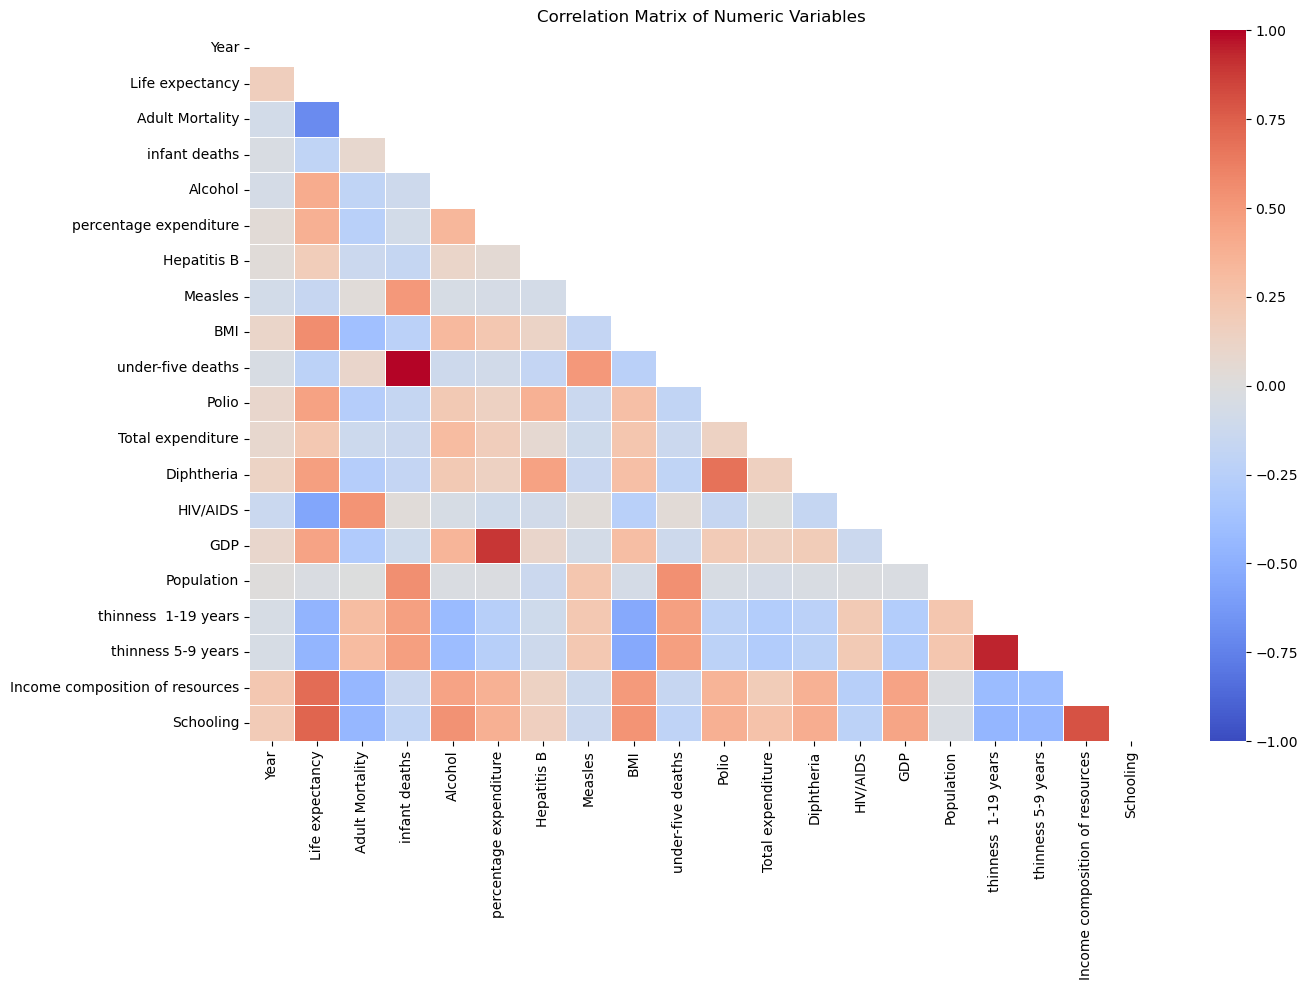

In [6]:
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()


print("\n CORRELATION WITH LIFE EXPECTANCY ")
print(corr_matrix['Life expectancy'].sort_values(ascending=False))

plt.figure(figsize=(14, 10))

# Masking for more readable data
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Plot the heatmap
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=False, 
    cmap='coolwarm', 
    linewidths=0.5, 
    vmin=-1, 
    vmax=1
)

plt.title("Correlation Matrix of Numeric Variables")
plt.tight_layout()

plt.savefig("correlation_matrix_presentation.png", dpi=300, bbox_inches='tight') #Saving for presentation


plt.show()

#### Saving the new dataset


In [7]:
df.to_csv("cleardataproject.csv", index=False)